In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("EduShield AI - ML Development")
print("Libraries imported successfully!")

EduShield AI - ML Development
Libraries imported successfully!


In [2]:
df = pd.read_csv(
    "../edushield_ai_student_dataset_2500.csv"
)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2500, 8)


,Dataset ID,Attendance,Internal marks,Previous GPA,Backlogs,Financial conditions,Risk category,Dropout label
0,STU0001,64.1,29.2,4.93,2,Moderate,High,1
1,STU0002,79.6,45.3,6.98,0,Severe,Medium,1
2,STU0003,47.6,27.9,6.82,1,Stable,High,1
3,STU0004,96.9,55.2,6.48,0,Severe,Medium,0
4,STU0005,85.6,54.9,6.05,0,Severe,Medium,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Dataset ID            2500 non-null   str    
 1   Attendance            2500 non-null   float64
 2   Internal marks        2500 non-null   float64
 3   Previous GPA          2500 non-null   float64
 4   Backlogs              2500 non-null   int64  
 5   Financial conditions  2500 non-null   str    
 6   Risk category         2500 non-null   str    
 7   Dropout label         2500 non-null   int64  
dtypes: float64(3), int64(2), str(3)
memory usage: 201.0 KB


In [4]:
df['Dropout label'].value_counts()

Dropout label
1    1378
0    1122
Name: count, dtype: int64

In [5]:
df.describe()

,Attendance,Internal marks,Previous GPA,Backlogs,Dropout label
count,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000
mean,75.190000,63.19116,6.815708,0.894800,0.551200
std,14.373621,17.76171,1.513805,0.949997,0.497471
min,20.000000,5.00000,1.000000,0.000000,0.000000
25%,65.275000,50.80000,5.770000,0.000000,0.000000
50%,75.500000,64.00000,6.820000,1.000000,1.000000
75%,85.900000,75.60000,7.900000,1.000000,1.000000
max,100.000000,100.00000,10.000000,5.000000,1.000000


In [6]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [7]:
print(df['Dropout label'].value_counts())

Dropout label
1    1378
0    1122
Name: count, dtype: int64


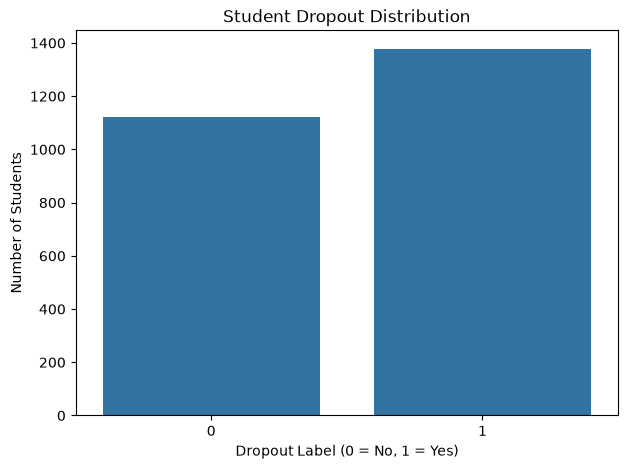

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Dropout label'
)

plt.title('Student Dropout Distribution')
plt.xlabel('Dropout Label (0 = No, 1 = Yes)')
plt.ylabel('Number of Students')

plt.show()

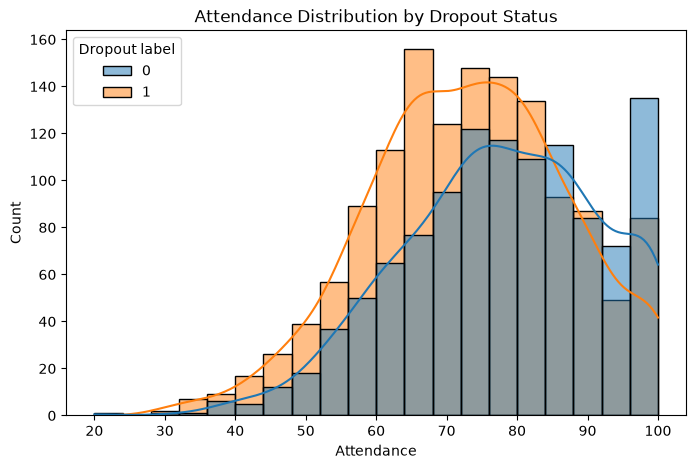

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Attendance',
    hue='Dropout label',
    kde=True,
    bins=20
)

plt.title('Attendance Distribution by Dropout Status')
plt.show()

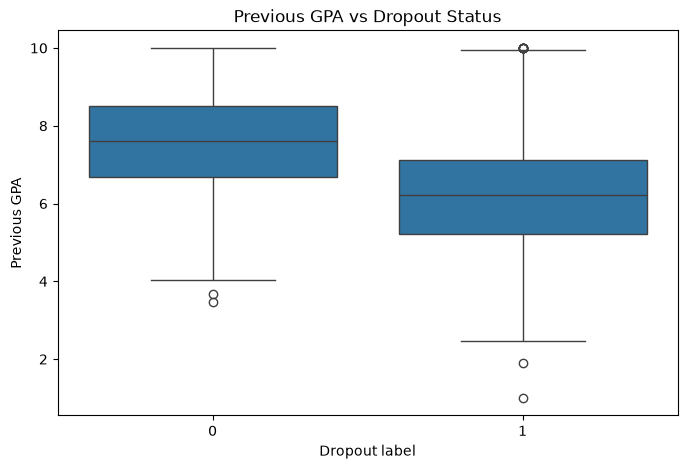

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Dropout label',
    y='Previous GPA'
)

plt.title('Previous GPA vs Dropout Status')
plt.show()

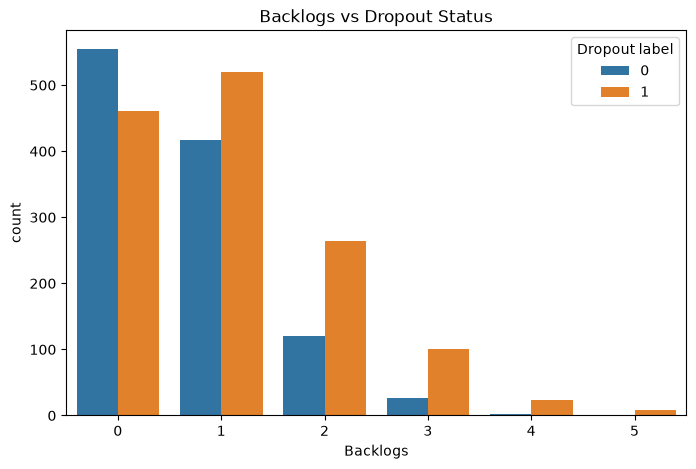

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Backlogs',
    hue='Dropout label'
)

plt.title('Backlogs vs Dropout Status')
plt.show()

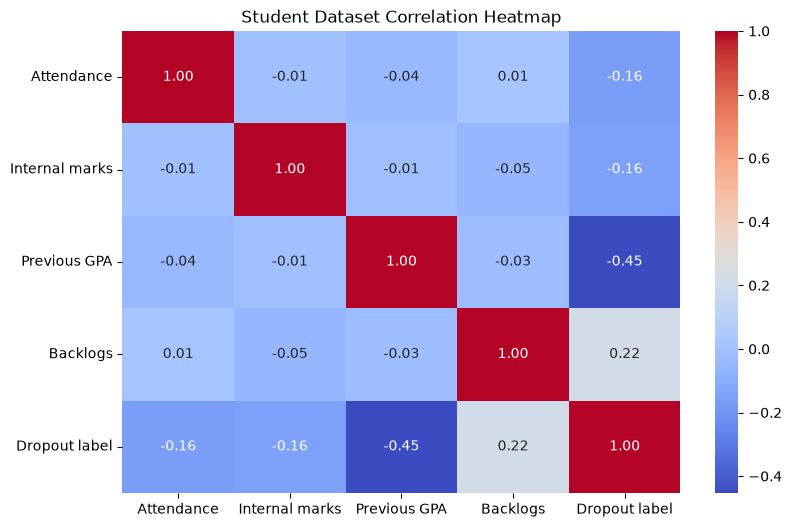

In [12]:
plt.figure(figsize=(9, 6))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Student Dataset Correlation Heatmap')
plt.show()

In [13]:
backlog_analysis = df.groupby('Backlogs')['Dropout label'].agg(
    ['count', 'sum', 'mean']
)

backlog_analysis.columns = [
    'Total Students',
    'Dropout Students',
    'Dropout Rate'
]

backlog_analysis['Dropout Rate'] *= 100

display(backlog_analysis)

,Total Students,Dropout Students,Dropout Rate
Backlogs,,,
0,1016,461,45.374016
1,937,520,55.496265
2,384,264,68.750000
3,128,101,78.906250
4,27,24,88.888889
5,8,8,100.000000


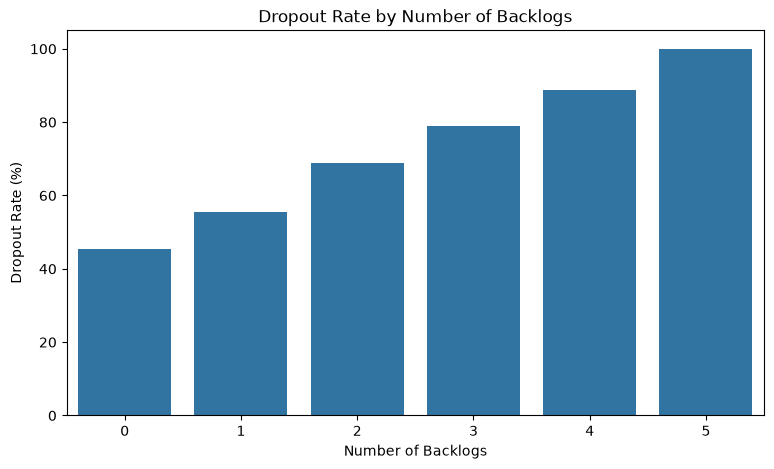

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=backlog_analysis.index,
    y=backlog_analysis['Dropout Rate']
)

plt.title('Dropout Rate by Number of Backlogs')
plt.xlabel('Number of Backlogs')
plt.ylabel('Dropout Rate (%)')

plt.show()

In [16]:
X = df.drop(
    columns=[
        'Dataset ID',
        'Risk category',
        'Dropout label'
    ]
)

y = df['Dropout label']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Attendance', 'Internal marks', 'Previous GPA', 'Backlogs', 'Financial conditions']

Target:
Dropout label


In [18]:
numerical_features = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['str', 'object', 'category', 'string']
).columns.tolist()

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)


Numerical: ['Attendance', 'Internal marks', 'Previous GPA', 'Backlogs']
Categorical: ['Financial conditions']


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1750, 5)
Validation: (375, 5)
Testing: (375, 5)


In [20]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score
)

import numpy as np
import pandas as pd

In [22]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    )

}

print("Three ML algorithms initialized successfully!")

Three ML algorithms initialized successfully!


In [23]:
trained_models = {}

for name, algorithm in models.items():

    pipeline = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('classifier', algorithm)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "training completed!")

Logistic Regression training completed!
Random Forest training completed!
Extra Trees training completed!


In [24]:
results = []

thresholds = np.linspace(0.10, 0.90, 161)

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    best_threshold = 0.5
    best_f2 = -1

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        score = fbeta_score(
            y_val,
            predictions,
            beta=2,
            zero_division=0
        )

        if score > best_f2:
            best_f2 = score
            best_threshold = threshold

    predictions = (probabilities >= best_threshold).astype(int)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0),
        'F2 Score': best_f2,
        'ROC-AUC': roc_auc_score(y_val, probabilities),
        'Threshold': best_threshold
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='F2 Score',
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC,Threshold
0,Logistic Regression,0.688000,0.640625,0.990338,0.777989,0.892857,0.863354,0.130
1,Random Forest,0.674667,0.633229,0.975845,0.768061,0.880558,0.825497,0.145
2,Extra Trees,0.690667,0.648208,0.961353,0.774319,0.876652,0.807540,0.190


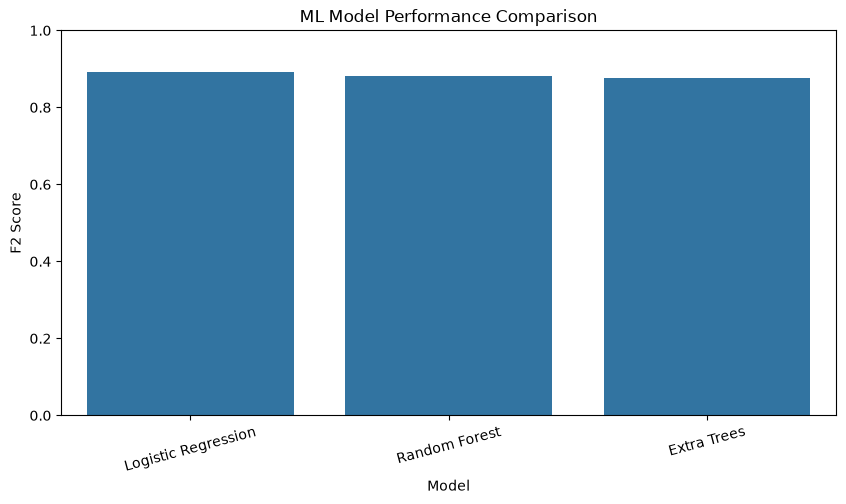

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='F2 Score'
)

plt.title('ML Model Performance Comparison')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

In [26]:
best_result = results_df.sort_values(
    by='F2 Score',
    ascending=False
).iloc[0]

best_model_name = best_result['Model']

best_model = trained_models[best_model_name]

best_threshold = best_result['Threshold']

print("Best Model:", best_model_name)
print("Best Validation F2:", best_result['F2 Score'])
print("Selected Threshold:", best_threshold)

Best Model: Logistic Regression
Best Validation F2: 0.8928571428571429
Selected Threshold: 0.13


In [27]:
# Predict probabilities
y_test_prob = best_model.predict_proba(X_test)[:, 1]

# Apply selected validation threshold
y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

print("Best Model:", best_model_name)
print("Threshold:", best_threshold)

Best Model: Logistic Regression
Threshold: 0.13


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    classification_report
)

print("FINAL TEST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Precision:",
      precision_score(y_test, y_test_pred))

print("Recall:",
      recall_score(y_test, y_test_pred))

print("F1 Score:",
      f1_score(y_test, y_test_pred))

print("F2 Score:",
      fbeta_score(y_test, y_test_pred, beta=2))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

FINAL TEST RESULTS
Accuracy: 0.6453333333333333
Precision: 0.6123076923076923
Recall: 0.9660194174757282
F1 Score: 0.7495291902071564
F2 Score: 0.865970409051349
ROC-AUC: 0.8160797380364221

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.25      0.39       169
           1       0.61      0.97      0.75       206

    accuracy                           0.65       375
   macro avg       0.74      0.61      0.57       375
weighted avg       0.72      0.65      0.59       375



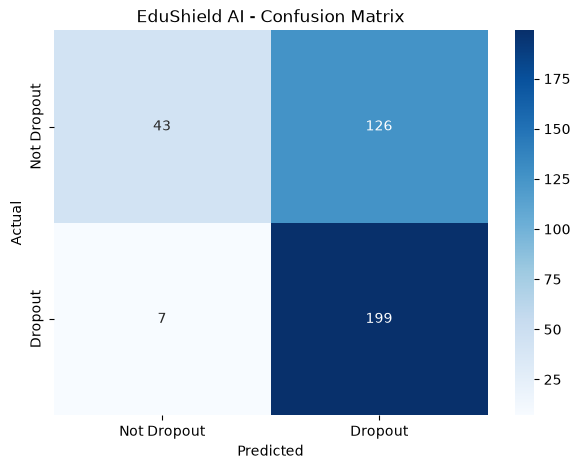

In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Dropout', 'Dropout'],
    yticklabels=['Not Dropout', 'Dropout']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('EduShield AI - Confusion Matrix')

plt.show()

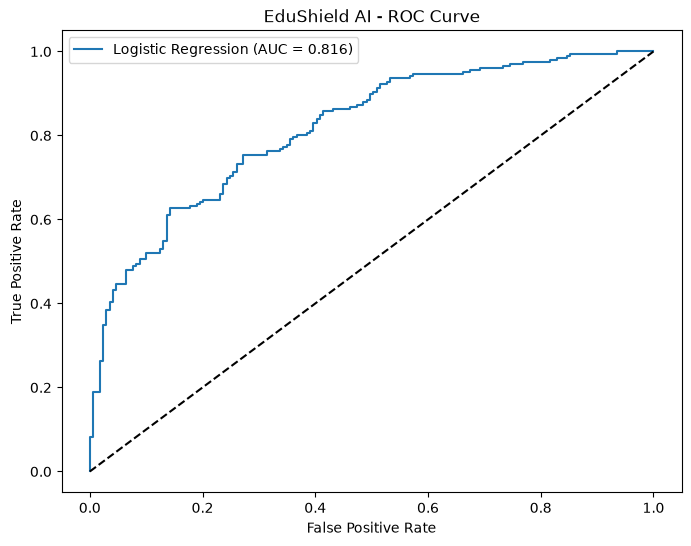

In [30]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_test_prob
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('EduShield AI - ROC Curve')
plt.legend()
plt.show()

In [31]:
import joblib
import json
from pathlib import Path

# Locate existing models folder
model_dir = Path("../../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Create model bundle
model_bundle = {
    "model": best_model,
    "threshold": float(best_threshold),
    "model_name": best_model_name,
    "features": X.columns.tolist()
}

# Save model
joblib.dump(
    model_bundle,
    model_dir / "dropout_model.joblib"
)

print("Model saved successfully!")
print("Location:", model_dir.resolve())

Model saved successfully!
Location: C:\Users\Vinay\OneDrive\Desktop\ct hackathon\models


In [32]:
metadata = {
    "model_name": best_model_name,
    "threshold": float(best_threshold),
    "features": X.columns.tolist(),
    "target": "Dropout label",
    "training_samples": len(X_train),
    "validation_samples": len(X_val),
    "testing_samples": len(X_test),
    "test_accuracy": float(accuracy_score(y_test, y_test_pred)),
    "test_precision": float(precision_score(y_test, y_test_pred)),
    "test_recall": float(recall_score(y_test, y_test_pred)),
    "test_f1": float(f1_score(y_test, y_test_pred)),
    "test_roc_auc": float(roc_auc_score(y_test, y_test_prob))
}

with open(model_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved!")

Metadata saved!


In [33]:
loaded_bundle = joblib.load(
    model_dir / "dropout_model.joblib"
)

loaded_model = loaded_bundle["model"]

print("Loaded:", loaded_bundle["model_name"])
print("Threshold:", loaded_bundle["threshold"])
print("Features:", loaded_bundle["features"])

Loaded: Logistic Regression
Threshold: 0.13
Features: ['Attendance', 'Internal marks', 'Previous GPA', 'Backlogs', 'Financial conditions']


In [34]:
import joblib
from pathlib import Path

model_dir = Path("../../models")

print(list(model_dir.iterdir()))

[WindowsPath('../../models/dropout_model.joblib'), WindowsPath('../../models/model_metadata.json')]
